In [2]:
import pandas as pd
import numpy as np
from plotnine import *

## Load the data
The Murder Accountability Project built this file from the FBI's homicide reports. It covers 929,433 U.S. homicides from 1976 to 2025. Each record includes the county, the victim's details, the weapon, and whether the case was solved.

In [3]:
df = pd.read_csv("../data/reports.csv")
df

,ID,CNTYFIPS,Ori,State,Agency,Agentype,Source,Solved,Year,Month,...,OffEthnic,Weapon,Relationship,Circumstance,Subcircum,VicCount,OffCount,FileDate,MSA,filter_$
0,197609001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,No,1976,September,...,Unknown or not reported,Other or type unknown,Relationship not determined,Other,NaN,0,0,30180.0,"Montgomery, AL",Not Selected
1,197701001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,January,...,Unknown or not reported,Other or type unknown,Acquaintance,Brawl due to influence of alcohol,NaN,0,0,30180.0,"Montgomery, AL",Not Selected
2,197703001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,March,...,Unknown or not reported,"Handgun - pistol, revolver, etc",Acquaintance,Other arguments,NaN,0,1,30180.0,"Montgomery, AL",Not Selected
3,197703001AL00401,"Autauga, AL",AL00401,Alabama,Prattville,Municipal police,FBI,Yes,1977,March,...,Unknown or not reported,Shotgun,Husband,Other arguments,NaN,0,0,30180.0,"Montgomery, AL",Not Selected
4,197708001AL00400,"Autauga, AL",AL00400,Alabama,Autauga County,Sheriff,FBI,Yes,1977,August,...,Unknown or not reported,Knife or cutting instrument,Acquaintance,Circumstances undetermined,NaN,0,0,30180.0,"Montgomery, AL",Not Selected
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
929428,198701001WY02300,"Weston, WY",WY02300,Wyoming,Weston County,Sheriff,FBI,Yes,1987,January,...,Unknown or not reported,Asphyxiation - includes death by gas,Son,All other manslaughter by negligence,NaN,0,0,61987.0,Rural Wyoming,Not Selected
929429,199412001WY02300,"Weston, WY",WY02300,Wyoming,Weston County,Sheriff,FBI,Yes,1994,December,...,Unknown or not reported,Other or type unknown,Acquaintance,All other manslaughter by negligence,NaN,0,0,22795.0,Rural Wyoming,Not Selected
929430,200405001WY02300,"Weston, WY",WY02300,Wyoming,Weston County,Sheriff,FBI,Yes,2004,May,...,Unknown or not reported,Other or type unknown,Girlfriend,Other arguments,NaN,0,0,90704.0,Rural Wyoming,Not Selected
929431,201106001WY02301,"Weston, WY",WY02301,Wyoming,Newcastle,Municipal police,FBI,No,2011,June,...,Unknown or not reported,"Handgun - pistol, revolver, etc",Relationship not determined,Circumstances undetermined,NaN,0,0,81711.0,Rural Wyoming,Not Selected


In [4]:
df.shape

(929433, 31)

## Look at the columns
Before choosing features, I had to sort out which columns are known when a murder happens and which are only filled in after it's solved.

In [5]:
df.columns

Index(['ID', 'CNTYFIPS', 'Ori', 'State', 'Agency', 'Agentype', 'Source',
       'Solved', 'Year', 'Month', 'Incident', 'ActionType', 'Homicide',
       'Situation', 'VicAge', 'VicSex', 'VicRace', 'VicEthnic', 'OffAge',
       'OffSex', 'OffRace', 'OffEthnic', 'Weapon', 'Relationship',
       'Circumstance', 'Subcircum', 'VicCount', 'OffCount', 'FileDate', 'MSA',
       'filter_$'],
      dtype='str')

Offender details, relationship, and circumstance are only known after a case is solved. If I kept them, the model would "predict" solved cases by seeing who did it.

In [6]:
df = df.drop(columns=['OffAge',  'OffSex', 'OffRace', 'OffEthnic', 'filter_$','Situation', 'Relationship', 'Circumstance', 'Subcircum', 'OffCount'])


In [ ]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 929433 entries, 0 to 929432
Data columns (total 21 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   ID          929433 non-null  str    
 1   CNTYFIPS    929433 non-null  str    
 2   Ori         929433 non-null  str    
 3   State       929433 non-null  str    
 4   Agency      929433 non-null  str    
 5   Agentype    929433 non-null  str    
 6   Source      929433 non-null  str    
 7   Solved      929433 non-null  str    
 8   Year        929433 non-null  int64  
 9   Month       929433 non-null  str    
 10  Incident    929433 non-null  int64  
 11  ActionType  929433 non-null  str    
 12  Homicide    929433 non-null  str    
 13  VicAge      929433 non-null  int64  
 14  VicSex      929433 non-null  str    
 15  VicRace     929433 non-null  str    
 16  VicEthnic   929433 non-null  str    
 17  Weapon      929433 non-null  str    
 18  VicCount    929433 non-null  int64  
 19  FileDate    9

In [7]:
for col in df.columns:
    print(df[col].value_counts().head(10))

ID
197702001NY05904    13
201405001CA04200    12
199204001FL05003    12
199310004CA01942    11
202301001CA01948    11
201512004CA03610    11
201811001CA05607    11
199504006OK05506    11
199504007OK05506    11
199504008OK05506    11
Name: count, dtype: int64
CNTYFIPS
Los Angeles, CA       56892
New York, NY          48463
Cook, IL              33372
Wayne, MI             25339
Harris, TX            24077
Philadelphia, PA      18455
Dallas, TX            15471
Baltimore city, MD    13419
Miami-Dade, FL        12575
Maricopa, AZ          12408
Name: count, dtype: int64
Ori
NY03030    48446
ILCPD00    31316
CA01942    29789
MI82349    22663
TXHPD00    18724
PAPEP00    18436
MDBPD00    13293
TXDPD00    12847
LANPD00     9928
DCMPD00     9867
Name: count, dtype: int64
State
California        133305
Texas              89997
New York           63761
Florida            52019
Illinois           40626
Michigan           39834
Pennsylvania       35676
Georgia            31102
North Carolina     3

I counted how many values in each column are "Unknown."

In [8]:
(df == "Unknown").sum()

ID                0
CNTYFIPS          0
Ori               0
State             0
Agency            1
Agentype          0
Source            0
Solved            0
Year              0
Month             0
Incident          0
ActionType        0
Homicide          0
VicAge            0
VicSex         1849
VicRace       12009
VicEthnic         0
Weapon            0
VicCount          0
FileDate          0
MSA               0
dtype: int64

I didn't drop unknown race or sex, since the missing information itself might affect whether a case gets solved.

## Create the baseline
The question is whether a murder gets solved, so this is my outcome.

In [9]:
df['Solved'].value_counts()
df['solved'] = (df['Solved']=='Yes').astype(int)
df['solved'].value_counts()


solved
1    657639
0    271794
Name: count, dtype: int64

About 71% of murders are solved.

I checked the highest victim ages.

In [10]:
df['VicAge'].value_counts().sort_index().tail()

VicAge
96        67
97        69
98        43
99       180
999    13577
Name: count, dtype: int64

999 is a code for "unknown," not a real age. Left in, it would look like a 999-year-old victim and throw off the model.

In [11]:
df['VicAge'] = df['VicAge'].replace([998, 999], np.nan)

I checked whether any incident ID shows up more than once.

In [12]:
df[df['ID'].duplicated(keep=False)].sort_values('ID').head(20)

,ID,CNTYFIPS,Ori,State,Agency,Agentype,Source,Solved,Year,Month,...,Homicide,VicAge,VicSex,VicRace,VicEthnic,Weapon,VicCount,FileDate,MSA,solved
72375,197601001CA01933,"Los Angeles, CA",CA01933,California,Inglewood,Municipal police,FBI,No,1976,January,...,Murder and non-negligent manslaughter,16.0,Male,Black,Unknown or not reported,"Firearm, type not stated",1,30180.0,"Los Angeles-Long Beach, CA",0
72376,197601001CA01933,"Los Angeles, CA",CA01933,California,Inglewood,Municipal police,FBI,No,1976,January,...,Murder and non-negligent manslaughter,25.0,Male,Black,Unknown or not reported,"Firearm, type not stated",1,30180.0,"Los Angeles-Long Beach, CA",0
72383,197601001CA01975,"Los Angeles, CA",CA01975,California,West Covina,Municipal police,FBI,No,1976,January,...,Murder and non-negligent manslaughter,42.0,Female,White,Unknown or not reported,Knife or cutting instrument,1,30180.0,"Los Angeles-Long Beach, CA",0
72384,197601001CA01975,"Los Angeles, CA",CA01975,California,West Covina,Municipal police,FBI,No,1976,January,...,Murder and non-negligent manslaughter,68.0,Male,White,Unknown or not reported,Knife or cutting instrument,1,30180.0,"Los Angeles-Long Beach, CA",0
131176,197601001CA02706,"Monterey, CA",CA02706,California,Monterey,Municipal police,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,42.0,Female,Asian,Unknown or not reported,Other or type unknown,1,30180.0,"Salinas, CA",1
131175,197601001CA02706,"Monterey, CA",CA02706,California,Monterey,Municipal police,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,28.0,Female,Asian,Unknown or not reported,Other or type unknown,1,30180.0,"Salinas, CA",1
204152,197601001DCMPD00,District of Columbia,DCMPD00,District of Columbia,Washington,Municipal police,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,28.0,Male,Black,Unknown or not reported,"Handgun - pistol, revolver, etc",1,30180.0,"Washington-Arlington-Alexandria, DC-VA-MD-WV",1
204151,197601001DCMPD00,District of Columbia,DCMPD00,District of Columbia,Washington,Municipal police,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,22.0,Male,Black,Unknown or not reported,"Handgun - pistol, revolver, etc",1,30180.0,"Washington-Arlington-Alexandria, DC-VA-MD-WV",1
215426,197601001FL00500,"Brevard, FL",FL00500,Florida,Brevard County,Sheriff,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,22.0,Male,White,Unknown or not reported,Shotgun,1,30180.0,"Palm Bay-Melbourne-Titusville, FL",1
215427,197601001FL00500,"Brevard, FL",FL00500,Florida,Brevard County,Sheriff,FBI,Yes,1976,January,...,Murder and non-negligent manslaughter,22.0,Male,White,Unknown or not reported,Shotgun,1,30180.0,"Palm Bay-Melbourne-Titusville, FL",1


One incident can have several victims. Each row is a different person, so I kept them all.

Accidental deaths aren't solved or unsolved the way murders are, so they would blur the pattern I'm looking for.

In [13]:
df = df[df['Homicide'] != 'Manslaughter by negligence']

In [14]:
df['Homicide'].value_counts()

Homicide
Murder and non-negligent manslaughter    905648
Name: count, dtype: int64

## Exploratory Visualizations
Before modeling, I wanted to see whether solve rates differ by victim race and weapon. If they do, those are worth giving the model.

In [15]:
top_counties = df["CNTYFIPS"].value_counts().head(10).index
top_weapons = df["Weapon"].value_counts().head(5).index
top10c = df[df["CNTYFIPS"].isin(top_counties)]
top10w = top10c[top10c["Weapon"].isin(top_weapons)]
by_year = df.groupby(["Year", "VicRace"], as_index=False)["solved"].mean()

In [16]:
plain = theme_bw() + theme(
    panel_grid_major=element_blank(),
    panel_grid_minor=element_blank(),
    panel_border=element_blank(),
    panel_background=element_blank(),
)

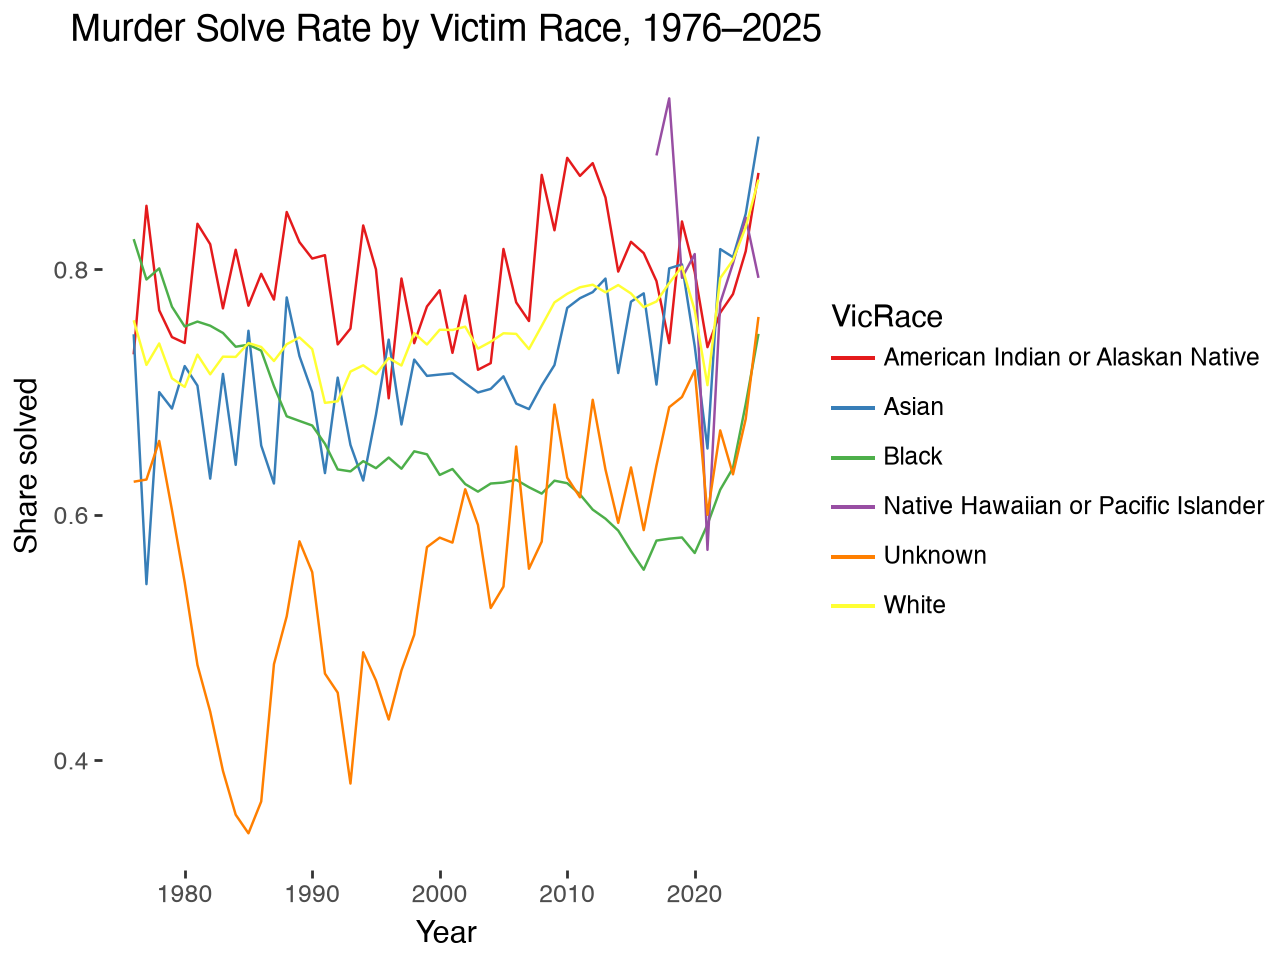

In [17]:

(ggplot(by_year, aes(x="Year", y="solved", color='VicRace'))
 + geom_line()
 + scale_color_brewer(palette="Set1")
 + plain
 + labs(title="Murder Solve Rate by Victim Race, 1976–2025",
        x="Year", y="Share solved"))


Murders of Black victims were solved more often than murders of white victims in the late 1970s, but that flipped in the 1980s and the gap kept growing after that. Since both lines move a lot over time, I kept Year as a feature so the model can account for those shifts.

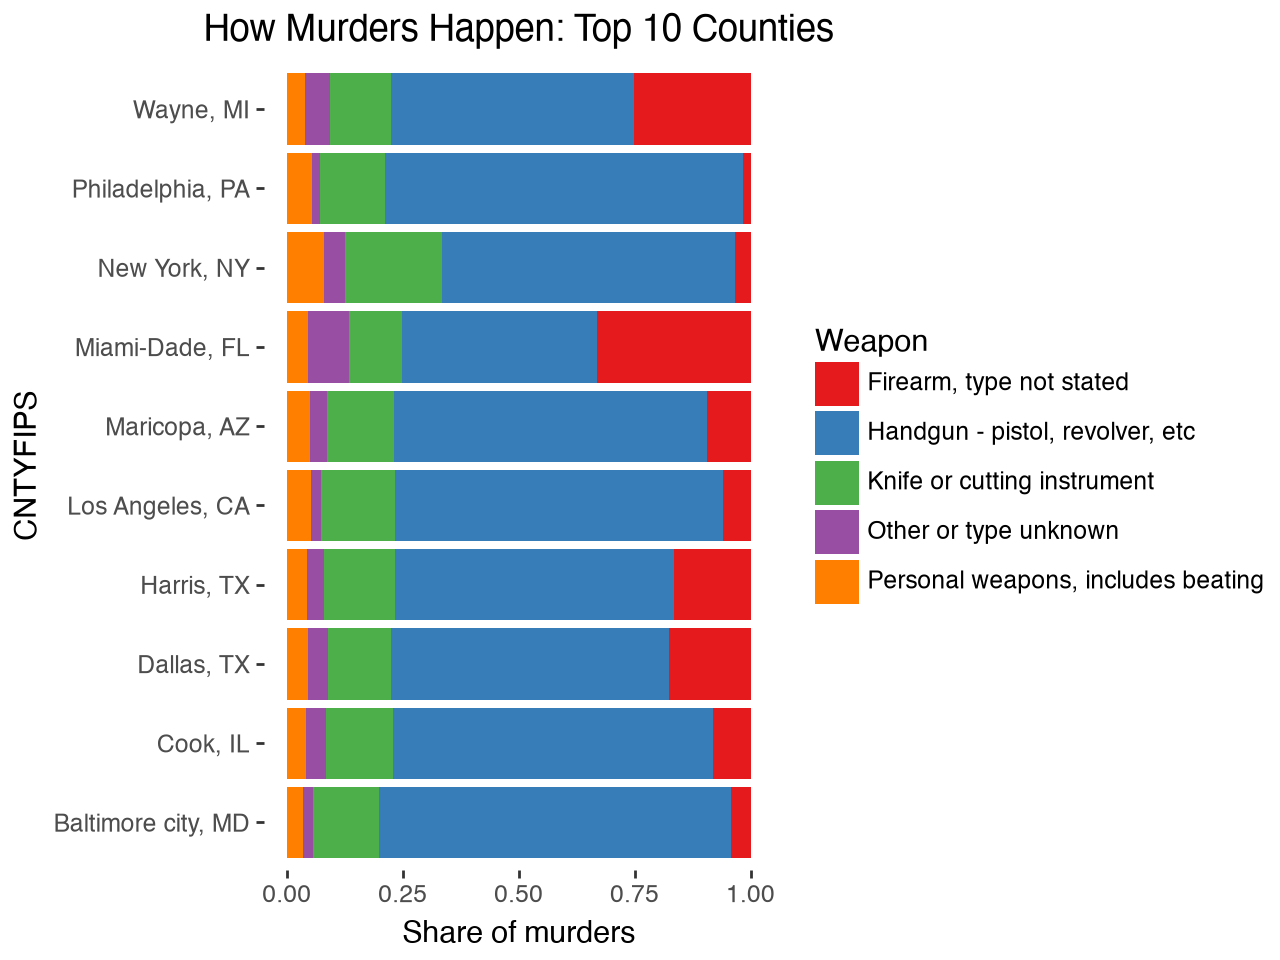

In [18]:
(ggplot(top10w, aes(x="CNTYFIPS", fill="Weapon"))
 + geom_bar(position="fill")
 + scale_fill_brewer(type="qual", palette="Set1")
 + coord_flip()
 + plain
 + labs(title="How Murders Happen: Top 10 Counties", y="Share of murders"))

Handguns are the most common weapon in every one of these counties. Miami-Dade and Wayne County (Detroit) have a bigger share of guns coded as "Firearm, type not stated," which tells me counties don't all record weapons the same way.

## Save Clean Data
I saved the cleaned data so the modeling notebook starts from here instead of repeating every cleaning step.

In [19]:
features = ['ID', 'CNTYFIPS', 'State', 'Agentype', 'Year', 'Month',
        'VicAge', 'VicSex', 'VicRace', 'VicEthnic', 'Weapon', 'VicCount', 'solved']
df = df[features]
df.to_csv("../data/clean.csv", index=False)